**Chapter 2 – End-to-end Machine Learning project**

*This notebook contains all the sample code and solutions to the exercises in chapter 2.*

<table align="left">
  <td>
    <a href="https://colab.research.google.com/github/ageron/handson-ml3/blob/main/02_end_to_end_machine_learning_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>
  </td>
  <td>
    <a target="_blank" href="https://kaggle.com/kernels/welcome?src=https://github.com/ageron/handson-ml3/blob/main/02_end_to_end_machine_learning_project.ipynb"><img src="https://kaggle.com/static/images/open-in-kaggle.svg" /></a>
  </td>
</table>

In [1]:
print("Welcome to Machine Learning!")

Welcome to Machine Learning!


This project requires Python 3.7 or above:

In [2]:
import sys

assert sys.version_info >= (3, 7)

It also requires Scikit-Learn ≥ 1.0.1:

In [3]:
from packaging import version
import sklearn

assert version.parse(sklearn.__version__) >= version.parse("1.0.1")

# Get the Data

*Welcome to Machine Learning car Corp.! Your task is to predict the price of a car, given the manufacture, the model, the sale price, the vehicle type, th engine size, horespower, wheelbase, width, length, curb weight, fuel efficency, and fuel capacity.*

## Download the Data

In [4]:
from pathlib import Path
import pandas as pd
import tarfile
import urllib.request

def load_housing_data():
    tarball_path = Path("datasets/housing.tgz")
    if not tarball_path.is_file():
        Path("datasets").mkdir(parents=True, exist_ok=True)
        url = "https://github.com/ageron/data/raw/main/housing.tgz"
        urllib.request.urlretrieve(url, tarball_path)
        with tarfile.open(tarball_path) as housing_tarball:
            housing_tarball.extractall(path="datasets")
    return pd.read_csv(Path("datasets/housing/housing.csv"))

car = load_housing_data()

Path("datasets").mkdir(parents=True, exist_ok=True)
car=pd.read_csv(Path("datasets/car sales/carsales.csv"))

In [5]:
car=car.drop("Latest_Launch", axis=1)

## Take a Quick Look at the Data Structure

In [6]:
car.head()

,Manufacturer,Model,Sales_in_thousands,Vehicle_type,Price_in_thousands,Engine_size,Horsepower,Wheelbase,Width,Length,Curb_weight,Fuel_capacity,Fuel_efficiency,Power_perf_factor
0,Acura,Integra,16.919,Passenger,21.50,1.8,140.0,101.2,67.3,172.4,2.639,13.2,28.0,58.280150
1,Acura,TL,39.384,Passenger,28.40,3.2,225.0,108.1,70.3,192.9,3.517,17.2,25.0,91.370778
2,Acura,CL,14.114,Passenger,NaN,3.2,225.0,106.9,70.6,192.0,3.470,17.2,26.0,NaN
3,Acura,RL,8.588,Passenger,42.00,3.5,210.0,114.6,71.4,196.6,3.850,18.0,22.0,91.389779
4,Audi,A4,20.397,Passenger,23.99,1.8,150.0,102.6,68.2,178.0,2.998,16.4,27.0,62.777639


In [7]:
car.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 157 entries, 0 to 156
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Manufacturer        157 non-null    object 
 1   Model               157 non-null    object 
 2   Sales_in_thousands  157 non-null    float64
 3   Vehicle_type        157 non-null    object 
 4   Price_in_thousands  155 non-null    float64
 5   Engine_size         156 non-null    float64
 6   Horsepower          156 non-null    float64
 7   Wheelbase           156 non-null    float64
 8   Width               156 non-null    float64
 9   Length              156 non-null    float64
 10  Curb_weight         155 non-null    float64
 11  Fuel_capacity       156 non-null    float64
 12  Fuel_efficiency     154 non-null    float64
 13  Power_perf_factor   155 non-null    float64
dtypes: float64(11), object(3)
memory usage: 17.3+ KB


In [8]:
car["Manufacturer"].value_counts()

Dodge         11
Ford          11
Toyota         9
Chevrolet      9
Mercedes-B     9
Mitsubishi     7
Nissan         7
Chrysler       7
Volvo          6
Oldsmobile     6
Lexus          6
Mercury        6
Pontiac        6
Volkswagen     6
Saturn         5
Cadillac       5
Honda          5
Plymouth       4
Acura          4
Buick          4
Audi           3
Jeep           3
Porsche        3
Hyundai        3
BMW            3
Lincoln        3
Saab           2
Subaru         2
Jaguar         1
Infiniti       1
Name: Manufacturer, dtype: int64

In [9]:
car.describe()

,Sales_in_thousands,Price_in_thousands,Engine_size,Horsepower,Wheelbase,Width,Length,Curb_weight,Fuel_capacity,Fuel_efficiency,Power_perf_factor
count,157.000000,155.000000,156.000000,156.000000,156.000000,156.000000,156.000000,155.000000,156.000000,154.000000,155.000000
mean,52.998076,27.390755,3.060897,185.948718,107.487179,71.150000,187.343590,3.378026,17.951923,23.844156,77.043591
std,68.029422,14.351653,1.044653,56.700321,7.641303,3.451872,13.431754,0.630502,3.887921,4.282706,25.142664
min,0.110000,9.235000,1.000000,55.000000,92.600000,62.600000,149.400000,1.895000,10.300000,15.000000,23.276272
25%,14.114000,18.017500,2.300000,149.500000,103.000000,68.400000,177.575000,2.971000,15.800000,21.000000,60.407707
50%,29.450000,22.799000,3.000000,177.500000,107.000000,70.550000,187.900000,3.342000,17.200000,24.000000,72.030917
75%,67.956000,31.947500,3.575000,215.000000,112.200000,73.425000,196.125000,3.799500,19.575000,26.000000,89.414878
max,540.561000,85.500000,8.000000,450.000000,138.700000,79.900000,224.500000,5.572000,32.000000,45.000000,188.144323


The following cell is not shown either in the book. It creates the `images/end_to_end_project` folder (if it doesn't already exist), and it defines the `save_fig()` function which is used through this notebook to save the figures in high-res for the book.

In [10]:
# extra code – code to save the figures as high-res PNGs for the book

IMAGES_PATH = Path() / "images" / "end_to_end_project"
IMAGES_PATH.mkdir(parents=True, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = IMAGES_PATH / f"{fig_id}.{fig_extension}"
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

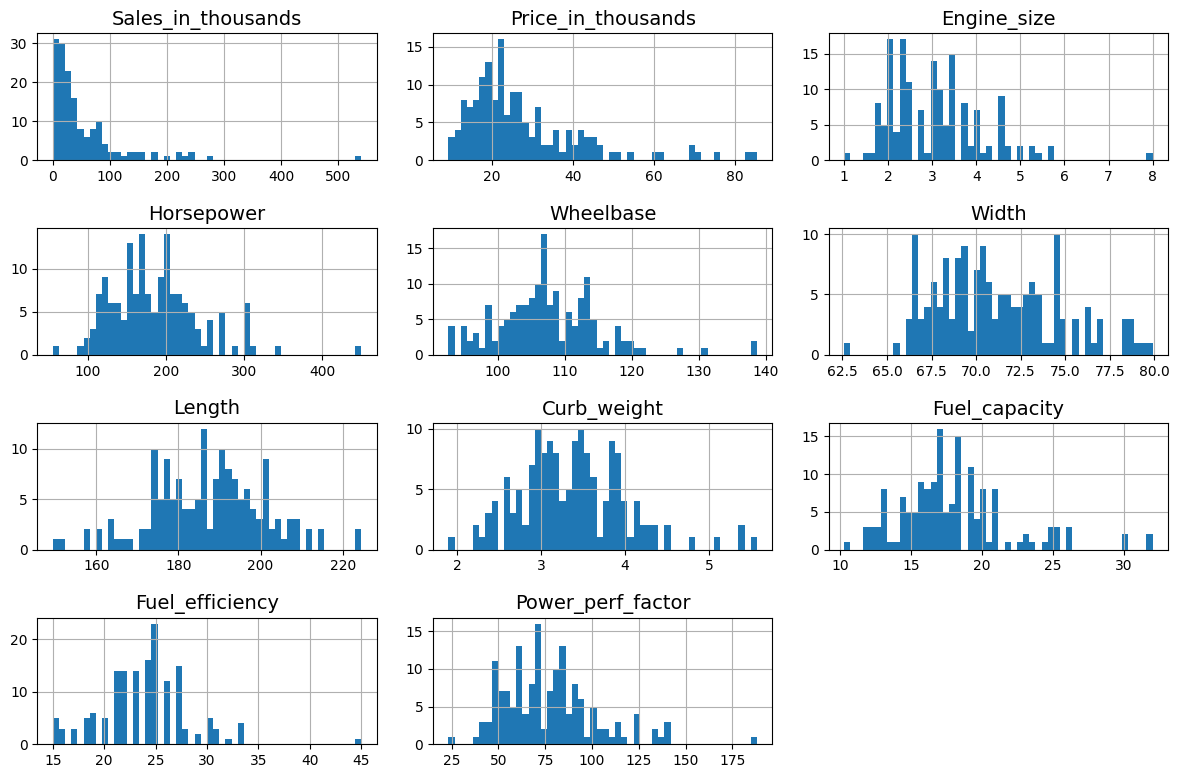

In [11]:
import matplotlib.pyplot as plt

# extra code – the next 5 lines define the default font sizes
plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

car.hist(bins=50, figsize=(12, 8))
save_fig("attribute_histogram_plots")  # extra code
plt.show()

## Create a Test Set

In [12]:
import numpy as np

def shuffle_and_split_data(data, test_ratio):
    shuffled_indices = np.random.permutation(len(data))
    test_set_size = int(len(data) * test_ratio)
    test_indices = shuffled_indices[:test_set_size]
    train_indices = shuffled_indices[test_set_size:]
    return data.iloc[train_indices], data.iloc[test_indices]

In [13]:
train_set, test_set = shuffle_and_split_data(car, 0.2)
len(train_set)

126

In [14]:
len(test_set)

31

To ensure that this notebook's outputs remain the same every time we run it, we need to set the random seed:

In [15]:
np.random.seed(42)

Sadly, this won't guarantee that this notebook will output exactly the same results as in the book, since there are other possible sources of variation. The most important is the fact that algorithms get tweaked over time when libraries evolve. So please tolerate some minor differences: hopefully, most of the outputs should be the same, or at least in the right ballpark.

Note: another source of randomness is the order of Python sets: it is based on Python's `hash()` function, which is randomly "salted" when Python starts up (this started in Python 3.3, to prevent some denial-of-service attacks). To remove this randomness, the solution is to set the `PYTHONHASHSEED` environment variable to `"0"` _before_ Python even starts up. Nothing will happen if you do it after that. Luckily, if you're running this notebook on Colab, the variable is already set for you.

In [16]:
from zlib import crc32

def is_id_in_test_set(identifier, test_ratio):
    return crc32(np.int64(identifier)) < test_ratio * 2**32

def split_data_with_id_hash(data, test_ratio, id_column):
    ids = data[id_column]
    in_test_set = ids.apply(lambda id_: is_id_in_test_set(id_, test_ratio))
    return data.loc[~in_test_set], data.loc[in_test_set]

In [17]:
car_with_id = car.reset_index()  # adds an `index` column
train_set, test_set = split_data_with_id_hash(car_with_id, 0.2, "index")

In [18]:
#car_with_id["id"] = car["longitude"] * 1000 + car["latitude"]
#train_set, test_set = split_data_with_id_hash(car_with_id, 0.2, "id")

In [19]:
from sklearn.model_selection import train_test_split

train_set, test_set = train_test_split(car, test_size=0.2, random_state=42)

In [20]:
#test_set["total_bedrooms"].isnull().sum()

To find the probability that a random sample of 1,000 people contains less than 48.5% female or more than 53.5% female when the population's female ratio is 51.1%, we use the [binomial distribution](https://en.wikipedia.org/wiki/Binomial_distribution). The `cdf()` method of the binomial distribution gives us the probability that the number of females will be equal or less than the given value.

In [21]:
# extra code – shows how to compute the 10.7% proba of getting a bad sample

from scipy.stats import binom

sample_size = 1000
ratio_female = 0.511
proba_too_small = binom(sample_size, ratio_female).cdf(485 - 1)
proba_too_large = 1 - binom(sample_size, ratio_female).cdf(535)
print(proba_too_small + proba_too_large)

0.10736798530929909


If you prefer simulations over maths, here's how you could get roughly the same result:

In [22]:
# extra code – shows another way to estimate the probability of bad sample

np.random.seed(42)

samples = (np.random.rand(100_000, sample_size) < ratio_female).sum(axis=1)
((samples < 485) | (samples > 535)).mean()

0.1071

In [23]:
car["Sales_cat"] = pd.cut(car["Sales_in_thousands"], 
                                   bins=[0, 14, 20, 30, 40, np.inf],
                                   labels=[1, 2, 3, 4, 5])

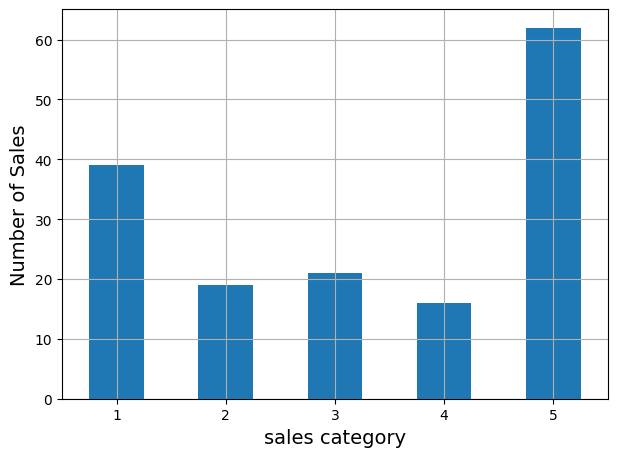

In [24]:
car["Sales_cat"].value_counts().sort_index().plot.bar(rot=0, grid=True)
plt.xlabel("sales category")
plt.ylabel("Number of Sales")
save_fig("car_income_cat_bar_plot")  # extra code
plt.show()

In [25]:
from sklearn.model_selection import StratifiedShuffleSplit

splitter = StratifiedShuffleSplit(n_splits=10, test_size=0.2, random_state=42)
strat_splits = []
for train_index, test_index in splitter.split(car, car["Sales_cat"]):
    strat_train_set_n = car.iloc[train_index]
    strat_test_set_n = car.iloc[test_index]
    strat_splits.append([strat_train_set_n, strat_test_set_n])

In [26]:
strat_train_set, strat_test_set = strat_splits[0]

It's much shorter to get a single stratified split:

In [27]:
strat_train_set, strat_test_set = train_test_split(
    car, test_size=0.2, stratify=car["Sales_cat"], random_state=42)

In [28]:
strat_test_set["Sales_cat"].value_counts() / len(strat_test_set)

5    0.40625
1    0.25000
2    0.12500
3    0.12500
4    0.09375
Name: Sales_cat, dtype: float64

In [29]:
# extra code – computes the data for Figure 2–10

def income_cat_proportions(data):
    return data["Sales_cat"].value_counts() / len(data)

train_set, test_set = train_test_split(car, test_size=0.2, random_state=42)

compare_props = pd.DataFrame({
    "Overall %": income_cat_proportions(car),
    "Stratified %": income_cat_proportions(strat_test_set),
    "Random %": income_cat_proportions(test_set),
}).sort_index()
compare_props.index.name = "Income Category"
compare_props["Strat. Error %"] = (compare_props["Stratified %"] /
                                   compare_props["Overall %"] - 1)
compare_props["Rand. Error %"] = (compare_props["Random %"] /
                                  compare_props["Overall %"] - 1)
(compare_props * 100).round(2)

,Overall %,Stratified %,Random %,Strat. Error %,Rand. Error %
Income Category,,,,,
1,24.84,25.00,28.12,0.64,13.22
2,12.10,12.50,18.75,3.29,54.93
3,13.38,12.50,6.25,-6.55,-53.27
4,10.19,9.38,12.50,-8.01,22.66
5,39.49,40.62,34.38,2.87,-12.95


In [30]:
for set_ in (strat_train_set, strat_test_set):
    set_.drop("Sales_cat", axis=1, inplace=True)

# Discover and Visualize the Data to Gain Insights

In [31]:
car = strat_train_set.copy()

## Visualizing Geographical Data

In [32]:
#car.plot(kind="scatter", x="longitude", y="latitude", grid=True)
#save_fig("bad_visualization_plot")  # extra code
#plt.show()

In [33]:
#car.plot(kind="scatter", x="longitude", y="latitude", grid=True, alpha=0.2)
#save_fig("better_visualization_plot")  # extra code
#plt.show()

In [34]:
#car.plot(kind="scatter", x="longitude", y="latitude", grid=True,
#             s=car["population"] / 100, label="population",
#             c="median_house_value", cmap="jet", colorbar=True,
#             legend=True, sharex=False, figsize=(10, 7))
#save_fig("car_prices_scatterplot")  # extra code
#plt.show()

The argument `sharex=False` fixes a display bug: without it, the x-axis values and label are not displayed (see: https://github.com/pandas-dev/pandas/issues/10611).

The next cell generates the first figure in the chapter (this code is not in the book). It's just a beautified version of the previous figure, with an image of California added in the background, nicer label names and no grid.

In [35]:
# extra code – this cell generates the first figure in the chapter

# Download the California image
#filename = "california.png"
#if not (IMAGES_PATH / filename).is_file():
#    homl3_root = "https://github.com/ageron/handson-ml3/raw/main/"
#    url = homl3_root + "images/end_to_end_project/" + filename
#    print("Downloading", filename)
#    urllib.request.urlretrieve(url, IMAGES_PATH / filename)
#
#car_renamed = car.rename(columns={
#    "latitude": "Latitude", "longitude": "Longitude",
#    "population": "Population",
#    "median_house_value": "Median house value (ᴜsᴅ)"})
#car_renamed.plot(
#             kind="scatter", x="Longitude", y="Latitude",
#             s=car_renamed["Population"] / 100, label="Population",
#             c="Median house value (ᴜsᴅ)", cmap="jet", colorbar=True,
#             legend=True, sharex=False, figsize=(10, 7))

#california_img = plt.imread(IMAGES_PATH / filename)
#axis = -124.55, -113.95, 32.45, 42.05
#plt.axis(axis)
#plt.imshow(california_img, extent=axis)

#save_fig("california_car_prices_plot")
#plt.show()

## Looking for Correlations

In [36]:
corr_matrix = car.corr()

C:\Users\raymo\AppData\Local\Temp\ipykernel_23676\535806077.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  corr_matrix = car.corr()


In [37]:
corr_matrix["Sales_in_thousands"].sort_values(ascending=False)

Sales_in_thousands    1.000000
Wheelbase             0.195112
Length                0.159993
Fuel_capacity         0.035275
Width                 0.032446
Fuel_efficiency       0.030190
Engine_size          -0.003484
Curb_weight          -0.026779
Horsepower           -0.217182
Power_perf_factor    -0.243583
Price_in_thousands   -0.334729
Name: Sales_in_thousands, dtype: float64

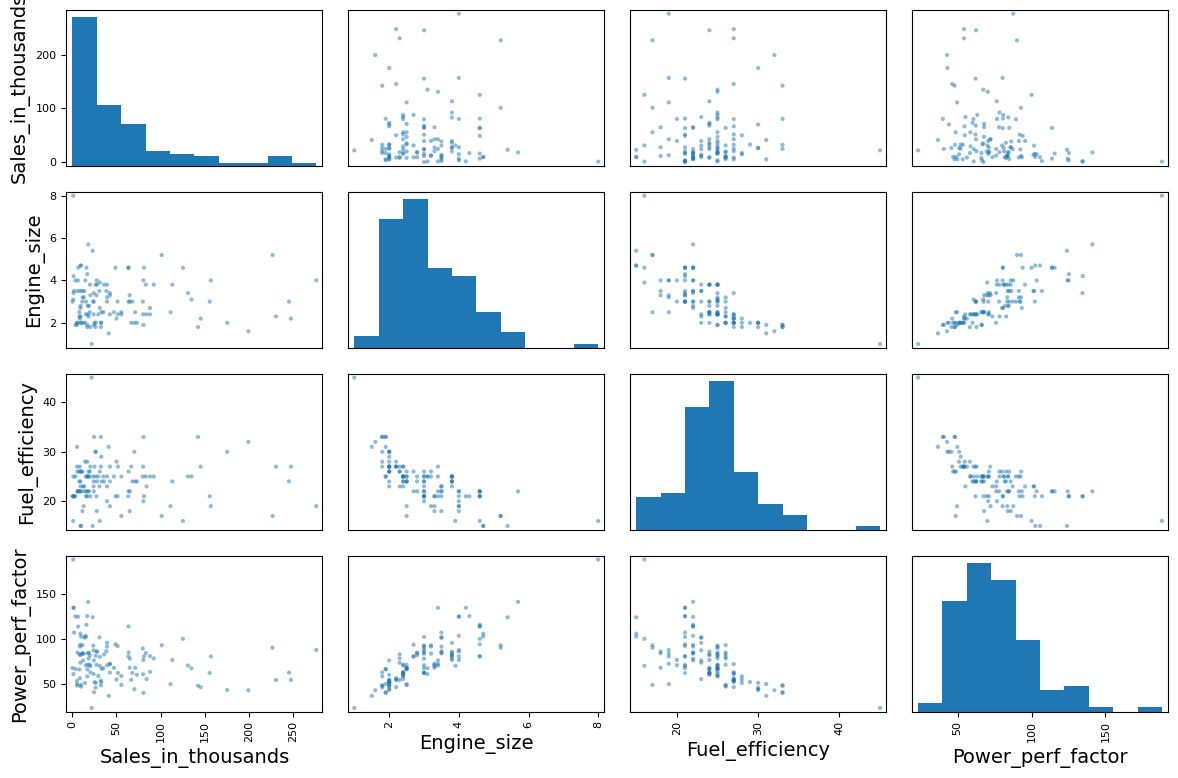

In [38]:
from pandas.plotting import scatter_matrix

attributes = ["Sales_in_thousands", "Model", "Engine_size",
              "Fuel_efficiency","Power_perf_factor","Vehicle_type","Model"]
scatter_matrix(car[attributes], figsize=(12, 8))
save_fig("scatter_matrix_plot")  # extra code
plt.show()

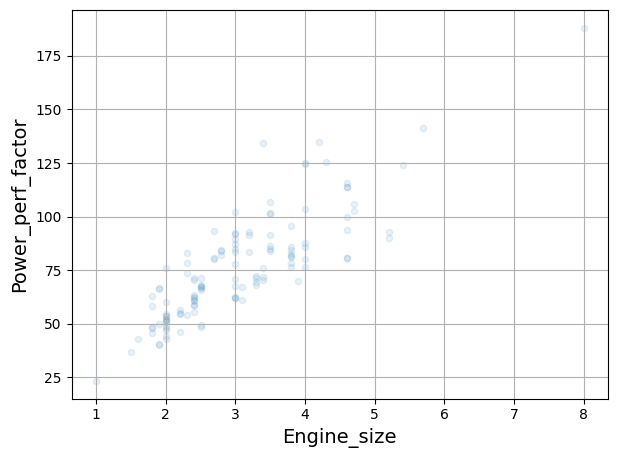

In [39]:
car.plot(kind="scatter", x="Engine_size", y="Power_perf_factor",
             alpha=0.1, grid=True)
save_fig("Engeinse size vs power performance factor")  # extra code
plt.show()

## Experimenting with Attribute Combinations

In [40]:
car["car_travel_dist"] = car["Fuel_efficiency"] * car["Fuel_capacity"]
car["horsepower_ratio"] = car["Horsepower"] / car["Engine_size"]
car["weight_length_ratio"] = car["Length"] / car["Curb_weight"]

In [41]:
corr_matrix = car.corr()
corr_matrix["Sales_in_thousands"].sort_values(ascending=False)

C:\Users\raymo\AppData\Local\Temp\ipykernel_23676\3237071462.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  corr_matrix = car.corr()


Sales_in_thousands     1.000000
Wheelbase              0.195112
Length                 0.159993
weight_length_ratio    0.125622
car_travel_dist        0.083253
Fuel_capacity          0.035275
Width                  0.032446
Fuel_efficiency        0.030190
Engine_size           -0.003484
Curb_weight           -0.026779
Horsepower            -0.217182
Power_perf_factor     -0.243583
Price_in_thousands    -0.334729
horsepower_ratio      -0.364768
Name: Sales_in_thousands, dtype: float64

# Prepare the Data for Machine Learning Algorithms

Let's revert to the original training set and separate the target (note that `strat_train_set.drop()` creates a copy of `strat_train_set` without the column, it doesn't actually modify `strat_train_set` itself, unless you pass `inplace=True`):

In [42]:
car = strat_train_set.drop("Sales_in_thousands", axis=1)
car_labels = strat_train_set["Sales_in_thousands"].copy()

## Data Cleaning

In the book 3 options are listed to handle the NaN values:

```python
car.dropna(subset=["total_bedrooms"], inplace=True)    # option 1

car.drop("total_bedrooms", axis=1)       # option 2

median = car["total_bedrooms"].median()  # option 3
car["total_bedrooms"].fillna(median, inplace=True)
```

For each option, we'll create a copy of `car` and work on that copy to avoid breaking `car`. We'll also show the output of each option, but filtering on the rows that originally contained a NaN value.

In [43]:
null_rows_idx = car.isnull().any(axis=1)
car.loc[null_rows_idx].head()

,Manufacturer,Model,Vehicle_type,Price_in_thousands,Engine_size,Horsepower,Wheelbase,Width,Length,Curb_weight,Fuel_capacity,Fuel_efficiency,Power_perf_factor
38,Dodge,Intrepid,Passenger,22.505,2.7,202.0,113.0,74.7,203.7,3.489,17.0,NaN,80.831470
109,Oldsmobile,Intrigue,Passenger,24.150,3.5,215.0,109.0,73.6,195.9,3.455,18.0,NaN,86.272523
33,Chrysler,Town & Country,Car,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
15,Cadillac,Seville,Passenger,44.475,4.6,275.0,112.2,75.0,201.0,NaN,18.5,22.0,115.621358


In [44]:
car_option1 = car.copy()

car_option1.dropna(subset=["Fuel_efficiency","Curb_weight"], inplace=True)  # option 1

car_option1.loc[null_rows_idx].head()

,Manufacturer,Model,Vehicle_type,Price_in_thousands,Engine_size,Horsepower,Wheelbase,Width,Length,Curb_weight,Fuel_capacity,Fuel_efficiency,Power_perf_factor


In [45]:
car_option2 = car.copy()

car_option2.drop("Fuel_efficiency", axis=1, inplace=True)  # option 2
car_option2.drop(33, axis=0, inplace=True)  # option 2

car_option2.loc[null_rows_idx].head()

,Manufacturer,Model,Vehicle_type,Price_in_thousands,Engine_size,Horsepower,Wheelbase,Width,Length,Curb_weight,Fuel_capacity,Power_perf_factor
38,Dodge,Intrepid,Passenger,22.505,2.7,202.0,113.0,74.7,203.7,3.489,17.0,80.831470
109,Oldsmobile,Intrigue,Passenger,24.150,3.5,215.0,109.0,73.6,195.9,3.455,18.0,86.272523
15,Cadillac,Seville,Passenger,44.475,4.6,275.0,112.2,75.0,201.0,NaN,18.5,115.621358


In [46]:
car_option3 = car.copy()

median = car["Fuel_efficiency"].median()
car_option3["Fuel_efficiency"].fillna(median, inplace=True)  # option 3

car_option3.loc[null_rows_idx].head()

,Manufacturer,Model,Vehicle_type,Price_in_thousands,Engine_size,Horsepower,Wheelbase,Width,Length,Curb_weight,Fuel_capacity,Fuel_efficiency,Power_perf_factor
38,Dodge,Intrepid,Passenger,22.505,2.7,202.0,113.0,74.7,203.7,3.489,17.0,24.0,80.831470
109,Oldsmobile,Intrigue,Passenger,24.150,3.5,215.0,109.0,73.6,195.9,3.455,18.0,24.0,86.272523
33,Chrysler,Town & Country,Car,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,24.0,NaN
15,Cadillac,Seville,Passenger,44.475,4.6,275.0,112.2,75.0,201.0,NaN,18.5,22.0,115.621358


In [47]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

Separating out the numerical attributes to use the `"median"` strategy (as it cannot be calculated on text attributes like `ocean_proximity`):

In [48]:
car_num = car.select_dtypes(include=[np.number])

In [49]:
imputer.fit(car_num)

SimpleImputer(strategy='median')

In [50]:
imputer.statistics_

array([ 22.65      ,   3.        , 175.        , 107.        ,
        70.35      , 187.25      ,   3.259     ,  17.05      ,
        24.        ,  72.16063614])

Check that this is the same as manually computing the median of each attribute:

In [51]:
car_num.median().values

array([ 22.65      ,   3.        , 175.        , 107.        ,
        70.35      , 187.25      ,   3.259     ,  17.05      ,
        24.        ,  72.16063614])

Transform the training set:

In [52]:
X = imputer.transform(car_num)

In [53]:
imputer.feature_names_in_

array(['Price_in_thousands', 'Engine_size', 'Horsepower', 'Wheelbase',
       'Width', 'Length', 'Curb_weight', 'Fuel_capacity',
       'Fuel_efficiency', 'Power_perf_factor'], dtype=object)

In [54]:
car_tr = pd.DataFrame(X, columns=car_num.columns,
                          index=car_num.index)

In [55]:
car_tr.loc[null_rows_idx].head()

,Price_in_thousands,Engine_size,Horsepower,Wheelbase,Width,Length,Curb_weight,Fuel_capacity,Fuel_efficiency,Power_perf_factor
38,22.505,2.7,202.0,113.0,74.70,203.70,3.489,17.00,24.0,80.831470
109,24.150,3.5,215.0,109.0,73.60,195.90,3.455,18.00,24.0,86.272523
33,22.650,3.0,175.0,107.0,70.35,187.25,3.259,17.05,24.0,72.160636
15,44.475,4.6,275.0,112.2,75.00,201.00,3.259,18.50,22.0,115.621358


In [56]:
imputer.strategy

'median'

In [57]:
car_tr = pd.DataFrame(X, columns=car_num.columns,
                          index=car_num.index)

In [58]:
car_tr.loc[null_rows_idx].head()  # not shown in the book

,Price_in_thousands,Engine_size,Horsepower,Wheelbase,Width,Length,Curb_weight,Fuel_capacity,Fuel_efficiency,Power_perf_factor
38,22.505,2.7,202.0,113.0,74.70,203.70,3.489,17.00,24.0,80.831470
109,24.150,3.5,215.0,109.0,73.60,195.90,3.455,18.00,24.0,86.272523
33,22.650,3.0,175.0,107.0,70.35,187.25,3.259,17.05,24.0,72.160636
15,44.475,4.6,275.0,112.2,75.00,201.00,3.259,18.50,22.0,115.621358


In [59]:
#from sklearn import set_config
#
# set_config(pandas_in_out=True)  # not available yet – see SLEP014

Now let's drop some outliers:

In [60]:
from sklearn.ensemble import IsolationForest

isolation_forest = IsolationForest(random_state=42)
outlier_pred = isolation_forest.fit_predict(X)

In [61]:
outlier_pred

array([ 1,  1,  1,  1,  1,  1,  1,  1, -1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1, -1,  1,  1,  1,  1, -1,  1,  1,
        1,  1,  1,  1,  1,  1, -1,  1, -1, -1,  1,  1, -1,  1,  1,  1,  1,
        1,  1,  1, -1,  1,  1, -1,  1,  1,  1, -1,  1,  1, -1,  1,  1,  1,
        1,  1,  1,  1,  1, -1, -1, -1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1, -1,  1, -1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1])

If you wanted to drop outliers, you would run the following code:

In [62]:
#car = car.iloc[outlier_pred == 1]
#car_labels = car_labels.iloc[outlier_pred == 1]

## Handling Text and Categorical Attributes

Now let's preprocess the categorical input feature, `Manufacturer`:

In [63]:
car_cat = car[["Manufacturer","Model","Vehicle_type"]]
car_cat=car_cat.drop(["Model","Vehicle_type"],axis=1)
car_cat.head(8)

,Manufacturer
118,Pontiac
4,Audi
73,Lexus
72,Lexus
103,Nissan
25,Chevrolet
70,Lexus
121,Pontiac


In [64]:
from sklearn.preprocessing import OrdinalEncoder

ordinal_encoder = OrdinalEncoder()
car_cat_encoded = ordinal_encoder.fit_transform(car_cat)

In [65]:
car_cat_encoded[:8]

array([[22.],
       [ 1.],
       [14.],
       [14.],
       [19.],
       [ 5.],
       [14.],
       [22.]])

In [66]:
ordinal_encoder.categories_

[array(['Acura', 'Audi', 'BMW', 'Buick', 'Cadillac', 'Chevrolet',
        'Chrysler', 'Dodge', 'Ford', 'Honda', 'Hyundai', 'Infiniti',
        'Jaguar', 'Jeep', 'Lexus', 'Lincoln', 'Mercedes-B', 'Mercury',
        'Mitsubishi', 'Nissan', 'Oldsmobile', 'Plymouth', 'Pontiac',
        'Porsche', 'Saab', 'Saturn', 'Subaru', 'Toyota', 'Volkswagen',
        'Volvo'], dtype=object)]

In [67]:
from sklearn.preprocessing import OneHotEncoder

cat_encoder = OneHotEncoder()
car_cat_1hot = cat_encoder.fit_transform(car_cat)

In [68]:
car_cat_1hot

<125x30 sparse matrix of type '<class 'numpy.float64'>'
	with 125 stored elements in Compressed Sparse Row format>

By default, the `OneHotEncoder` class returns a sparse array, but we can convert it to a dense array if needed by calling the `toarray()` method:

In [69]:
car_cat_1hot.toarray()

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 1.]])

Alternatively, you can set `sparse=False` when creating the `OneHotEncoder`:

In [70]:
cat_encoder = OneHotEncoder(sparse=False)
car_cat_1hot = cat_encoder.fit_transform(car_cat)
car_cat_1hot

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 1.]])

In [71]:
cat_encoder.categories_

[array(['Acura', 'Audi', 'BMW', 'Buick', 'Cadillac', 'Chevrolet',
        'Chrysler', 'Dodge', 'Ford', 'Honda', 'Hyundai', 'Infiniti',
        'Jaguar', 'Jeep', 'Lexus', 'Lincoln', 'Mercedes-B', 'Mercury',
        'Mitsubishi', 'Nissan', 'Oldsmobile', 'Plymouth', 'Pontiac',
        'Porsche', 'Saab', 'Saturn', 'Subaru', 'Toyota', 'Volkswagen',
        'Volvo'], dtype=object)]

In [72]:
Model_list=car["Model"].unique()
Manufacturer_list=car["Manufacturer"].unique()

In [73]:
df_test = pd.DataFrame({"Manufacturer": Manufacturer_list })
pd.get_dummies(df_test)
df_test

,Manufacturer
0,Pontiac
1,Audi
2,Lexus
3,Nissan
4,Chevrolet
5,Lincoln
6,Toyota
7,Ford
8,Jeep
9,BMW


In [74]:
cat_encoder.transform(df_test)

array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 1

In [75]:
df_test_unknown = pd.DataFrame({"Manufacturer": Manufacturer_list })
pd.get_dummies(df_test_unknown)

,Manufacturer_Acura,Manufacturer_Audi,Manufacturer_BMW,Manufacturer_Buick,Manufacturer_Cadillac,Manufacturer_Chevrolet,Manufacturer_Chrysler,Manufacturer_Dodge,Manufacturer_Ford,Manufacturer_Honda,...,Manufacturer_Oldsmobile,Manufacturer_Plymouth,Manufacturer_Pontiac,Manufacturer_Porsche,Manufacturer_Saab,Manufacturer_Saturn,Manufacturer_Subaru,Manufacturer_Toyota,Manufacturer_Volkswagen,Manufacturer_Volvo
0,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
1,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
7,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [76]:
cat_encoder.handle_unknown = "ignore"
cat_encoder.transform(df_test_unknown)

array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 1

In [77]:
cat_encoder.feature_names_in_

array(['Manufacturer'], dtype=object)

In [78]:
cat_encoder.get_feature_names_out()

array(['Manufacturer_Acura', 'Manufacturer_Audi', 'Manufacturer_BMW',
       'Manufacturer_Buick', 'Manufacturer_Cadillac',
       'Manufacturer_Chevrolet', 'Manufacturer_Chrysler',
       'Manufacturer_Dodge', 'Manufacturer_Ford', 'Manufacturer_Honda',
       'Manufacturer_Hyundai', 'Manufacturer_Infiniti',
       'Manufacturer_Jaguar', 'Manufacturer_Jeep', 'Manufacturer_Lexus',
       'Manufacturer_Lincoln', 'Manufacturer_Mercedes-B',
       'Manufacturer_Mercury', 'Manufacturer_Mitsubishi',
       'Manufacturer_Nissan', 'Manufacturer_Oldsmobile',
       'Manufacturer_Plymouth', 'Manufacturer_Pontiac',
       'Manufacturer_Porsche', 'Manufacturer_Saab', 'Manufacturer_Saturn',
       'Manufacturer_Subaru', 'Manufacturer_Toyota',
       'Manufacturer_Volkswagen', 'Manufacturer_Volvo'], dtype=object)

In [79]:
df_output = pd.DataFrame(cat_encoder.transform(df_test_unknown),
                         columns=cat_encoder.get_feature_names_out(),
                         index=df_test_unknown.index)

In [80]:
df_output

,Manufacturer_Acura,Manufacturer_Audi,Manufacturer_BMW,Manufacturer_Buick,Manufacturer_Cadillac,Manufacturer_Chevrolet,Manufacturer_Chrysler,Manufacturer_Dodge,Manufacturer_Ford,Manufacturer_Honda,...,Manufacturer_Oldsmobile,Manufacturer_Plymouth,Manufacturer_Pontiac,Manufacturer_Porsche,Manufacturer_Saab,Manufacturer_Saturn,Manufacturer_Subaru,Manufacturer_Toyota,Manufacturer_Volkswagen,Manufacturer_Volvo
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Feature Scaling

In [81]:
from sklearn.preprocessing import MinMaxScaler

min_max_scaler = MinMaxScaler(feature_range=(-1, 1))
car_num_min_max_scaled = min_max_scaler.fit_transform(car_num)

In [82]:
from sklearn.preprocessing import StandardScaler

std_scaler = StandardScaler()
car_num_std_scaled = std_scaler.fit_transform(car_num)

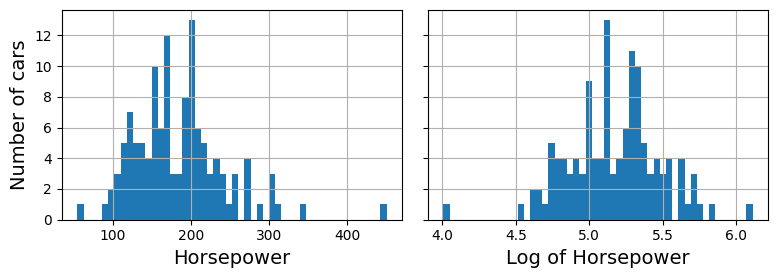

In [83]:
# extra code – this cell generates Figure 2–17
fig, axs = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
car["Horsepower"].hist(ax=axs[0], bins=50)
car["Horsepower"].apply(np.log).hist(ax=axs[1], bins=50)
axs[0].set_xlabel("Horsepower")
axs[1].set_xlabel("Log of Horsepower")
axs[0].set_ylabel("Number of cars")
save_fig("long_tail_plot")
plt.show()

What if we replace each value with its percentile?

In [84]:
# extra code – just shows that we get a uniform distribution
#percentiles = [np.percentile(car["median_income"], p)
#               for p in range(1, 100)]
#flattened_median_income = pd.cut(car["median_income"],
#                                 bins=[-np.inf] + percentiles + [np.inf],
#                                 labels=range(1, 100 + 1))
#flattened_median_income.hist(bins=50)
#plt.xlabel("Median income percentile")
#plt.ylabel("Number of districts")
#plt.show()
# Note: incomes below the 1st percentile are labeled 1, and incomes above the
# 99th percentile are labeled 100. This is why the distribution below ranges
# from 1 to 100 (not 0 to 100).

In [85]:
car[["Horsepower"]]=car[["Horsepower"]].fillna(car[["Horsepower"]].median())

In [86]:
from sklearn.metrics.pairwise import rbf_kernel
age_simil_35 = rbf_kernel(car[["Horsepower"]], [[35]], gamma=0.1)

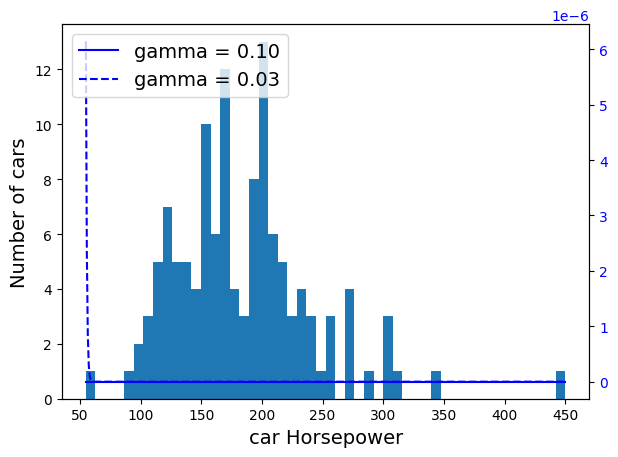

In [87]:
# extra code – this cell generates Figure 2–18

ages = np.linspace(car["Horsepower"].min(),
                   car["Horsepower"].max(),
                   500).reshape(-1, 1)
gamma1 = 0.1
gamma2 = 0.03
rbf1 = rbf_kernel(ages, [[35]], gamma=gamma1)
rbf2 = rbf_kernel(ages, [[35]], gamma=gamma2)

fig, ax1 = plt.subplots()

ax1.set_xlabel("car Horsepower")
ax1.set_ylabel("Number of cars")
ax1.hist(car["Horsepower"], bins=50)

ax2 = ax1.twinx()  # create a twin axis that shares the same x-axis
color = "blue"
ax2.plot(ages, rbf1, color=color, label="gamma = 0.10")
ax2.plot(ages, rbf2, color=color, label="gamma = 0.03", linestyle="--")
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylabel("", color=color)

plt.legend(loc="upper left")
save_fig("age_similarity_plot")
plt.show()

In [88]:
car_labels

118    51.645
4      20.397
73      6.375
72      3.334
103    79.853
        ...  
151    16.957
96      7.998
89     81.174
14     63.729
152     3.545
Name: Sales_in_thousands, Length: 125, dtype: float64

In [89]:
from sklearn.linear_model import LinearRegression

target_scaler = StandardScaler()
scaled_labels = target_scaler.fit_transform(car_labels.to_frame())

model = LinearRegression()
model.fit(car[["Horsepower"]], scaled_labels)
some_new_data = car[["Horsepower"]].iloc[:5]  # pretend this is new data

scaled_predictions = model.predict(some_new_data)
predictions = target_scaler.inverse_transform(scaled_predictions)

In [90]:
predictions

array([[58.31676645],
       [58.31676645],
       [28.02113889],
       [25.85716549],
       [42.73615799]])

In [91]:
from sklearn.compose import TransformedTargetRegressor

model = TransformedTargetRegressor(LinearRegression(),
                                   transformer=StandardScaler())
model.fit(car[["Horsepower"]], car_labels)
predictions = model.predict(some_new_data)

In [92]:
predictions

array([58.31676645, 58.31676645, 28.02113889, 25.85716549, 42.73615799])

## Custom Transformers

To create simple transformers:

In [93]:
from sklearn.preprocessing import FunctionTransformer

log_transformer = FunctionTransformer(np.log, inverse_func=np.exp)
log_pop = log_transformer.transform(car[["Fuel_efficiency"]])

In [94]:
rbf_transformer = FunctionTransformer(rbf_kernel,
                                      kw_args=dict(Y=[[35.]], gamma=0.1))
age_simil_35 = rbf_transformer.transform(car[["Horsepower"]])

In [95]:
age_simil_35

array([[0.00000000e+000],
       [0.00000000e+000],
       [0.00000000e+000],
       [0.00000000e+000],
       [0.00000000e+000],
       [1.66815663e-314],
       [0.00000000e+000],
       [0.00000000e+000],
       [0.00000000e+000],
       [0.00000000e+000],
       [0.00000000e+000],
       [1.66815663e-314],
       [0.00000000e+000],
       [0.00000000e+000],
       [0.00000000e+000],
       [0.00000000e+000],
       [0.00000000e+000],
       [0.00000000e+000],
       [0.00000000e+000],
       [0.00000000e+000],
       [0.00000000e+000],
       [0.00000000e+000],
       [0.00000000e+000],
       [0.00000000e+000],
       [0.00000000e+000],
       [0.00000000e+000],
       [0.00000000e+000],
       [3.24027146e-184],
       [0.00000000e+000],
       [5.12099002e-245],
       [0.00000000e+000],
       [0.00000000e+000],
       [0.00000000e+000],
       [0.00000000e+000],
       [0.00000000e+000],
       [0.00000000e+000],
       [0.00000000e+000],
       [0.00000000e+000],
       [0.00

In [96]:
#sf_coords = 37.7749, -122.41
#sf_transformer = FunctionTransformer(rbf_kernel,
#                                     kw_args=dict(Y=[sf_coords], gamma=0.1))
#sf_simil = sf_transformer.transform(car[["latitude", "longitude"]])

In [97]:
#sf_simil

In [98]:
ratio_transformer = FunctionTransformer(lambda X: X[:, [0]] / X[:, [1]])
ratio_transformer.transform(np.array([[1., 2.], [3., 4.]]))

array([[0.5 ],
       [0.75]])

In [99]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_array, check_is_fitted

class StandardScalerClone(BaseEstimator, TransformerMixin):
    def __init__(self, with_mean=True):  # no *args or **kwargs!
        self.with_mean = with_mean

    def fit(self, X, y=None):  # y is required even though we don't use it
        X = check_array(X)  # checks that X is an array with finite float values
        self.mean_ = X.mean(axis=0)
        self.scale_ = X.std(axis=0)
        self.n_features_in_ = X.shape[1]  # every estimator stores this in fit()
        return self  # always return self!

    def transform(self, X):
        check_is_fitted(self)  # looks for learned attributes (with trailing _)
        X = check_array(X)
        assert self.n_features_in_ == X.shape[1]
        if self.with_mean:
            X = X - self.mean_
        return X / self.scale_

In [100]:
from sklearn.cluster import KMeans

class ClusterSimilarity(BaseEstimator, TransformerMixin):
    def __init__(self, n_clusters=10, gamma=1.0, random_state=None):
        self.n_clusters = n_clusters
        self.gamma = gamma
        self.random_state = random_state

    def fit(self, X, y=None, sample_weight=None):
        self.kmeans_ = KMeans(self.n_clusters, random_state=self.random_state)
        self.kmeans_.fit(X, sample_weight=sample_weight)
        return self  # always return self!

    def transform(self, X):
        return rbf_kernel(X, self.kmeans_.cluster_centers_, gamma=self.gamma)
    
    def get_feature_names_out(self, names=None):
        return [f"Cluster {i} similarity" for i in range(self.n_clusters)]

In [101]:
# cluster_simil = ClusterSimilarity(n_clusters=10, gamma=1., random_state=42)
# similarities = cluster_simil.fit_transform(car[["latitude", "longitude"]],
#                                            sample_weight=car_labels)

In [102]:
# similarities[:3].round(2)

In [103]:
# # extra code – this cell generates Figure 2–19

# car_renamed = car.rename(columns={
#     "latitude": "Latitude", "longitude": "Longitude",
#     "population": "Population",
#     "median_house_value": "Median house value (ᴜsᴅ)"})
# car_renamed["Max cluster similarity"] = similarities.max(axis=1)

# car_renamed.plot(kind="scatter", x="Longitude", y="Latitude", grid=True,
#                      s=car_renamed["Population"] / 100, label="Population",
#                      c="Max cluster similarity",
#                      cmap="jet", colorbar=True,
#                      legend=True, sharex=False, figsize=(10, 7))
# plt.plot(cluster_simil.kmeans_.cluster_centers_[:, 1],
#          cluster_simil.kmeans_.cluster_centers_[:, 0],
#          linestyle="", color="black", marker="X", markersize=20,
#          label="Cluster centers")
# plt.legend(loc="upper right")
# save_fig("district_cluster_plot")
# plt.show()

## Transformation Pipelines

Now let's build a pipeline to preprocess the numerical attributes:

In [104]:
from sklearn.pipeline import Pipeline

num_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("standardize", StandardScaler()),
])

In [105]:
from sklearn.pipeline import make_pipeline

num_pipeline = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())

In [106]:
from sklearn import set_config

set_config(display='diagram')

num_pipeline

Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('standardscaler', StandardScaler())])

In [107]:
car_num_prepared = num_pipeline.fit_transform(car_num)
car_num_prepared[:2].round(2)

array([[-0.37, -0.61, -0.6 , -0.44, -0.77, -0.4 , -0.7 , -0.73,  0.7 ,
        -0.57],
       [-0.18, -1.19, -0.6 , -0.64, -0.82, -0.7 , -0.55, -0.35,  0.7 ,
        -0.54]])

In [108]:
def monkey_patch_get_signature_names_out():
    """Monkey patch some classes which did not handle get_feature_names_out()
       correctly in Scikit-Learn 1.0.*."""
    from inspect import Signature, signature, Parameter
    import pandas as pd
    from sklearn.impute import SimpleImputer
    from sklearn.pipeline import make_pipeline, Pipeline
    from sklearn.preprocessing import FunctionTransformer, StandardScaler

    default_get_feature_names_out = StandardScaler.get_feature_names_out

    if not hasattr(SimpleImputer, "get_feature_names_out"):
      print("Monkey-patching SimpleImputer.get_feature_names_out()")
      SimpleImputer.get_feature_names_out = default_get_feature_names_out

    if not hasattr(FunctionTransformer, "get_feature_names_out"):
        print("Monkey-patching FunctionTransformer.get_feature_names_out()")
        orig_init = FunctionTransformer.__init__
        orig_sig = signature(orig_init)

        def __init__(*args, feature_names_out=None, **kwargs):
            orig_sig.bind(*args, **kwargs)
            orig_init(*args, **kwargs)
            args[0].feature_names_out = feature_names_out

        __init__.__signature__ = Signature(
            list(signature(orig_init).parameters.values()) + [
                Parameter("feature_names_out", Parameter.KEYWORD_ONLY)])

        def get_feature_names_out(self, names=None):
            if callable(self.feature_names_out):
                return self.feature_names_out(self, names)
            assert self.feature_names_out == "one-to-one"
            return default_get_feature_names_out(self, names)

        FunctionTransformer.__init__ = __init__
        FunctionTransformer.get_feature_names_out = get_feature_names_out

monkey_patch_get_signature_names_out()

In [109]:
df_car_num_prepared = pd.DataFrame(
    car_num_prepared, columns=num_pipeline.get_feature_names_out(),
    index=car_num.index)

In [110]:
df_car_num_prepared.head(2)  # extra code

,Price_in_thousands,Engine_size,Horsepower,Wheelbase,Width,Length,Curb_weight,Fuel_capacity,Fuel_efficiency,Power_perf_factor
118,-0.372814,-0.614019,-0.600265,-0.435909,-0.766140,-0.401879,-0.699874,-0.727455,0.70079,-0.571742
4,-0.183153,-1.188943,-0.600265,-0.640140,-0.823944,-0.696157,-0.549155,-0.346816,0.70079,-0.540845


In [111]:
num_pipeline.steps

[('simpleimputer', SimpleImputer(strategy='median')),
 ('standardscaler', StandardScaler())]

In [112]:
num_pipeline[1]

StandardScaler()

In [113]:
num_pipeline[:-1]

Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median'))])

In [114]:
num_pipeline.named_steps["simpleimputer"]

SimpleImputer(strategy='median')

In [115]:
num_pipeline.set_params(simpleimputer__strategy="median")

Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('standardscaler', StandardScaler())])

In [116]:
from sklearn.compose import ColumnTransformer

num_attribs = ["Sales_in_thousands", "Price_in_thousands", "Engine_size", "Horsepower",
               "Wheelbase", "Width", "households", "Curb_weight","Fuel_capacity",
               "Fuel_efficiency","Power_perf_factor"]
cat_attribs = ["Manufacturer","Model","Vehicle_vtype"]

cat_pipeline = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore"))

preprocessing = ColumnTransformer([
    ("num", num_pipeline, num_attribs),
    ("cat", cat_pipeline, cat_attribs),
])

In [117]:
from sklearn.compose import make_column_selector, make_column_transformer

preprocessing = make_column_transformer(
    (num_pipeline, make_column_selector(dtype_include=np.number)),
    (cat_pipeline, make_column_selector(dtype_include=object)),
)

In [118]:
car_prepared = preprocessing.fit_transform(car)

In [119]:
(car_prepared)


<125x167 sparse matrix of type '<class 'numpy.float64'>'
	with 1625 stored elements in Compressed Sparse Row format>

In [120]:
# extra code – shows that we can get a DataFrame out if we want
#car_prepared_fr = pd.DataFrame(
#    car_prepared,
#    columns=preprocessing.get_feature_names_out(),
#    index=car.index)
#car_prepared_fr.head(2)

In [121]:
# def column_ratio(X):
#     return X[:, [0]] / X[:, [1]]

# def ratio_name(function_transformer, feature_names_in):
#     return ["ratio"]  # feature names out

# def ratio_pipeline():
#     return make_pipeline(
#         SimpleImputer(strategy="median"),
#         FunctionTransformer(column_ratio, feature_names_out=ratio_name),
#         StandardScaler())

# log_pipeline = make_pipeline(
#     SimpleImputer(strategy="median"),
#     FunctionTransformer(np.log, feature_names_out="one-to-one"),
#     StandardScaler())
# cluster_simil = ClusterSimilarity(n_clusters=10, gamma=1., random_state=42)
# default_num_pipeline = make_pipeline(SimpleImputer(strategy="median"),
#                                      StandardScaler())
# preprocessing = ColumnTransformer([
#         ("bedrooms", ratio_pipeline(), ["total_bedrooms", "total_rooms"]),
#         ("rooms_per_house", ratio_pipeline(), ["total_rooms", "households"]),
#         ("people_per_house", ratio_pipeline(), ["population", "households"]),
#         ("log", log_pipeline, ["total_bedrooms", "total_rooms", "population",
#                                "households", "median_income"]),
#         ("geo", cluster_simil, ["latitude", "longitude"]),
#         ("cat", cat_pipeline, make_column_selector(dtype_include=object)),
#     ],
#     remainder=default_num_pipeline)  # one column remaining: car_median_age

In [122]:
car_prepared = preprocessing.fit_transform(car)
car_prepared.shape

(125, 167)

In [123]:
preprocessing.get_feature_names_out()

array(['pipeline-1__Price_in_thousands', 'pipeline-1__Engine_size',
       'pipeline-1__Horsepower', 'pipeline-1__Wheelbase',
       'pipeline-1__Width', 'pipeline-1__Length',
       'pipeline-1__Curb_weight', 'pipeline-1__Fuel_capacity',
       'pipeline-1__Fuel_efficiency', 'pipeline-1__Power_perf_factor',
       'pipeline-2__Manufacturer_Acura', 'pipeline-2__Manufacturer_Audi',
       'pipeline-2__Manufacturer_BMW', 'pipeline-2__Manufacturer_Buick',
       'pipeline-2__Manufacturer_Cadillac',
       'pipeline-2__Manufacturer_Chevrolet',
       'pipeline-2__Manufacturer_Chrysler',
       'pipeline-2__Manufacturer_Dodge', 'pipeline-2__Manufacturer_Ford',
       'pipeline-2__Manufacturer_Honda',
       'pipeline-2__Manufacturer_Hyundai',
       'pipeline-2__Manufacturer_Infiniti',
       'pipeline-2__Manufacturer_Jaguar', 'pipeline-2__Manufacturer_Jeep',
       'pipeline-2__Manufacturer_Lexus',
       'pipeline-2__Manufacturer_Lincoln',
       'pipeline-2__Manufacturer_Mercedes-B',
   

# Select and Train a Model

## Training and Evaluating on the Training Set

In [124]:
from sklearn.linear_model import LinearRegression

lin_reg = make_pipeline(preprocessing, LinearRegression())
lin_reg.fit(car, car_labels)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('pipeline-1',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x0000022AD6CD18E0>),
                                                 ('pipeline-2',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x0000022AD6CD10A0>)])),
                ('linearregression', LinearRegression())])

Let's try the full preprocessing pipeline on a few training instances:

In [125]:
car_predictions = lin_reg.predict(car)
car_predictions[:5].round(-2)  # -2 = rounded to the nearest hundred

array([100.,   0.,   0.,   0., 100.])

Compare against the actual values:

In [126]:
car_labels.iloc[:5].values

array([51.645, 20.397,  6.375,  3.334, 79.853])

In [127]:
# extra code – computes the error ratios discussed in the book
error_ratios = car_predictions[:5].round(-2) / car_labels.iloc[:5].values - 1
print(", ".join([f"{100 * ratio:.1f}%" for ratio in error_ratios]))

93.6%, -100.0%, -100.0%, -100.0%, 25.2%


In [128]:
from sklearn.metrics import mean_squared_error

lin_rmse = mean_squared_error(car_labels, car_predictions,
                              squared=False)
lin_rmse

0.0011529651573196624

In [129]:
from sklearn.tree import DecisionTreeRegressor

tree_reg = make_pipeline(preprocessing, DecisionTreeRegressor(random_state=42))
tree_reg.fit(car, car_labels)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('pipeline-1',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x0000022AD6CD18E0>),
                                                 ('pipeline-2',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x0000022AD6CD10A0>)])),
                ('decisiontreeregressor',
                 DecisionTreeRegressor(random_state=42))])

In [130]:
car_predictions = tree_reg.predict(car)
tree_rmse = mean_squared_error(car_labels, car_predictions,
                              squared=False)
tree_rmse

0.0

## Better Evaluation Using Cross-Validation

In [131]:
from sklearn.model_selection import cross_val_score

tree_rmses = -cross_val_score(tree_reg, car, car_labels,
                              scoring="neg_root_mean_squared_error", cv=10)

In [132]:
pd.Series(tree_rmses).describe()

count    10.000000
mean     64.187122
std      20.590208
min      33.657628
25%      46.082535
50%      69.440035
75%      76.571654
max      95.240547
dtype: float64

In [133]:
# extra code – computes the error stats for the linear model
lin_rmses = -cross_val_score(lin_reg, car, car_labels,
                              scoring="neg_root_mean_squared_error", cv=10)
pd.Series(lin_rmses).describe()

count    10.000000
mean     45.330203
std      13.974229
min      22.641862
25%      36.909586
50%      44.968885
75%      54.834803
max      66.716285
dtype: float64

**Warning:** the following cell may take a few minutes to run:

In [134]:
from sklearn.ensemble import RandomForestRegressor

forest_reg = make_pipeline(preprocessing,
                           RandomForestRegressor(random_state=42))
forest_rmses = -cross_val_score(forest_reg, car, car_labels,
                                scoring="neg_root_mean_squared_error", cv=10)

In [135]:
pd.Series(forest_rmses).describe()

count    10.000000
mean     52.612489
std      16.938053
min      22.127992
25%      42.333024
50%      49.496552
75%      62.316114
max      80.319340
dtype: float64

Let's compare this RMSE measured using cross-validation (the "validation error") with the RMSE measured on the training set (the "training error"):

In [136]:
forest_reg.fit(car, car_labels)
car_predictions = forest_reg.predict(car)
forest_rmse = mean_squared_error(car_labels, car_predictions,
                                 squared=False)
forest_rmse

20.06461401611103

The training error is much lower than the validation error, which usually means that the model has overfit the training set. Another possible explanation may be that there's a mismatch between the training data and the validation data, but it's not the case here, since both came from the same dataset that we shuffled and split in two parts.

# Fine-Tune Your Model

## Grid Search

**Warning:** the following cell may take a few minutes to run:

In [137]:
from sklearn.model_selection import GridSearchCV

full_pipeline = Pipeline([
    ("preprocessing", preprocessing),
    ("random_forest", RandomForestRegressor(random_state=42)),
])
param_grid = [
    {'random_forest__max_features': [4, 6, 8]},
    {'random_forest__max_features': [6, 8, 10]},
]
grid_search = GridSearchCV(full_pipeline, param_grid, cv=3,
                           scoring='neg_root_mean_squared_error')
grid_search.fit(car, car_labels)

GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('preprocessing',
                                        ColumnTransformer(transformers=[('pipeline-1',
                                                                         Pipeline(steps=[('simpleimputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('standardscaler',
                                                                                          StandardScaler())]),
                                                                         <sklearn.compose._column_transformer.make_column_selector object at 0x0000022AD6CD18E0>),
                                                                        ('pipeline-2',
                                                                         Pipeline(steps=[('simpleimputer',
                                                                                          Simpl...requent')),
                                                                                         ('onehotencoder',
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         <sklearn.compose._column_transformer.make_column_selector object at 0x0000022AD6CD10A0>)])),
                                       ('random_forest',
                                        RandomForestRegressor(random_state=42))]),
             param_grid=[{'random_forest__max_features': [4, 6, 8]},
                         {'random_forest__max_features': [6, 8, 10]}],
             scoring='neg_root_mean_squared_error')

You can get the full list of hyperparameters available for tuning by looking at `full_pipeline.get_params().keys()`:

In [138]:
# extra code – shows part of the output of get_params().keys()
print(str(full_pipeline.get_params().keys())[:1000] + "...")

dict_keys(['memory', 'steps', 'verbose', 'preprocessing', 'random_forest', 'preprocessing__n_jobs', 'preprocessing__remainder', 'preprocessing__sparse_threshold', 'preprocessing__transformer_weights', 'preprocessing__transformers', 'preprocessing__verbose', 'preprocessing__verbose_feature_names_out', 'preprocessing__pipeline-1', 'preprocessing__pipeline-2', 'preprocessing__pipeline-1__memory', 'preprocessing__pipeline-1__steps', 'preprocessing__pipeline-1__verbose', 'preprocessing__pipeline-1__simpleimputer', 'preprocessing__pipeline-1__standardscaler', 'preprocessing__pipeline-1__simpleimputer__add_indicator', 'preprocessing__pipeline-1__simpleimputer__copy', 'preprocessing__pipeline-1__simpleimputer__fill_value', 'preprocessing__pipeline-1__simpleimputer__missing_values', 'preprocessing__pipeline-1__simpleimputer__strategy', 'preprocessing__pipeline-1__simpleimputer__verbose', 'preprocessing__pipeline-1__standardscaler__copy', 'preprocessing__pipeline-1__standardscaler__with_mean', '

The best hyperparameter combination found:

In [139]:
grid_search.best_params_

{'random_forest__max_features': 6}

In [140]:
grid_search.best_estimator_

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('pipeline-1',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x0000022AD5DA1190>),
                                                 ('pipeline-2',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x0000022AD8C8FE50>)])),
                ('random_forest',
                 RandomForestRegressor(max_features=6, random_state=42))])

Let's look at the score of each hyperparameter combination tested during the grid search:

In [141]:
cv_res = pd.DataFrame(grid_search.cv_results_)
cv_res.sort_values(by="mean_test_score", ascending=False, inplace=True)

# extra code – these few lines of code just make the DataFrame look nicer
cv_res = cv_res[["param_random_forest__max_features", "split0_test_score",
                 "split1_test_score", "split2_test_score", "mean_test_score"]]
score_cols = ["split0", "split1",  "mean_test_rmse"]
cv_res.columns = ["n_clusters", "max_features"] + score_cols
cv_res[score_cols] = -cv_res[score_cols].round().astype(np.int64)

cv_res.head()

,n_clusters,max_features,split0,split1,mean_test_rmse
1,6,-46.114155,65,45,52
3,6,-46.114155,65,45,52
0,4,-45.044778,65,46,52
5,10,-46.324373,66,44,52
2,8,-46.317638,67,44,52


## Randomized Search

In [142]:
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingRandomSearchCV

Try 30 (`n_iter` × `cv`) random combinations of hyperparameters:

**Warning:** the following cell may take a few minutes to run:

In [143]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

param_distribs = {                  'random_forest__max_features': randint(low=2, high=20)}

rnd_search = RandomizedSearchCV(
    full_pipeline, param_distributions=param_distribs, n_iter=10, cv=3,
    scoring='neg_root_mean_squared_error', random_state=42)

rnd_search.fit(car, car_labels)

RandomizedSearchCV(cv=3,
                   estimator=Pipeline(steps=[('preprocessing',
                                              ColumnTransformer(transformers=[('pipeline-1',
                                                                               Pipeline(steps=[('simpleimputer',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('standardscaler',
                                                                                                StandardScaler())]),
                                                                               <sklearn.compose._column_transformer.make_column_selector object at 0x0000022AD6CD18E0>),
                                                                              ('pipeline-2',
                                                                               Pipeline(steps=[('simpleimputer'...
                                                                                                OneHotEncoder(handle_unknown='ignore'))]),
                                                                               <sklearn.compose._column_transformer.make_column_selector object at 0x0000022AD6CD10A0>)])),
                                             ('random_forest',
                                              RandomForestRegressor(random_state=42))]),
                   param_distributions={'random_forest__max_features': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x0000022AD2F3BE80>},
                   random_state=42, scoring='neg_root_mean_squared_error')

In [144]:
# extra code – displays the random search results
cv_res = pd.DataFrame(rnd_search.cv_results_)
cv_res.sort_values(by="mean_test_score", ascending=False, inplace=True)
cv_res = cv_res[[
                 "param_random_forest__max_features", "split0_test_score",
                 "split1_test_score", "split2_test_score", "mean_test_score"]]
cv_res.columns = ["n_clusters", "max_features"] + score_cols
cv_res[score_cols] = -cv_res[score_cols].round().astype(np.int64)
cv_res.head()

,n_clusters,max_features,split0,split1,mean_test_rmse
7,5,-45.408654,65,45,52
9,4,-45.044778,65,46,52
1,16,-46.393424,67,44,52
2,12,-45.669738,66,45,52
5,12,-45.669738,66,45,52


**Bonus section: how to choose the sampling distribution for a hyperparameter**

* `scipy.stats.randint(a, b+1)`: for hyperparameters with _discrete_ values that range from a to b, and all values in that range seem equally likely.
* `scipy.stats.uniform(a, b)`: this is very similar, but for _continuous_ hyperparameters.
* `scipy.stats.geom(1 / scale)`: for discrete values, when you want to sample roughly in a given scale. E.g., with scale=1000 most samples will be in this ballpark, but ~10% of all samples will be <100 and ~10% will be >2300.
* `scipy.stats.expon(scale)`: this is the continuous equivalent of `geom`. Just set `scale` to the most likely value.
* `scipy.stats.reciprocal(a, b)`: when you have almost no idea what the optimal hyperparameter value's scale is. If you set a=0.01 and b=100, then you're just as likely to sample a value between 0.01 and 0.1 as a value between 10 and 100.


Here are plots of the probability mass functions (for discrete variables), and probability density functions (for continuous variables) for `randint()`, `uniform()`, `geom()` and `expon()`:

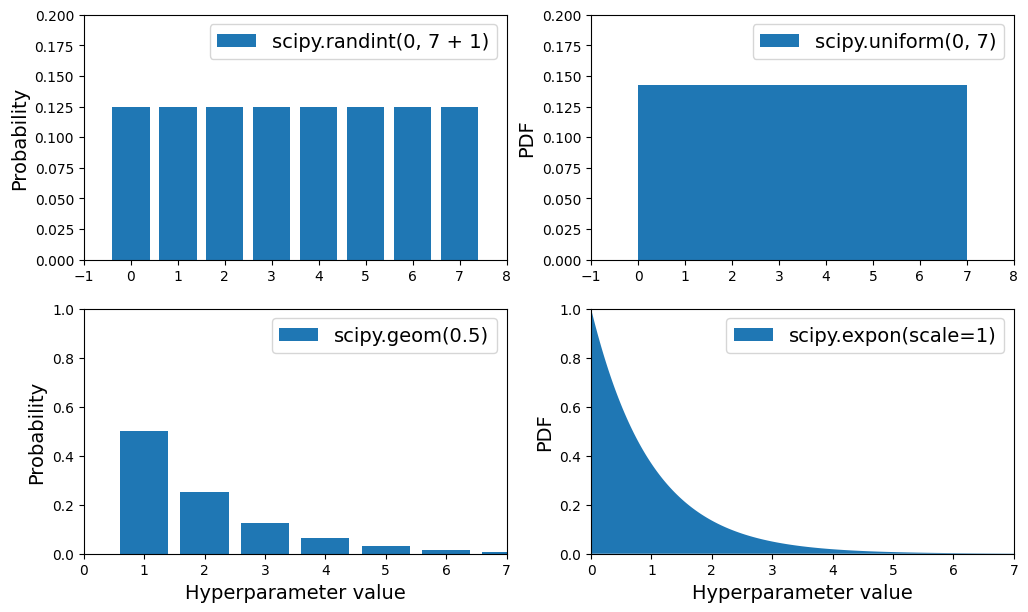

In [145]:
# extra code – plots a few distributions you can use in randomized search

from scipy.stats import randint, uniform, geom, expon

xs1 = np.arange(0, 7 + 1)
randint_distrib = randint(0, 7 + 1).pmf(xs1)

xs2 = np.linspace(0, 7, 500)
uniform_distrib = uniform(0, 7).pdf(xs2)

xs3 = np.arange(0, 7 + 1)
geom_distrib = geom(0.5).pmf(xs3)

xs4 = np.linspace(0, 7, 500)
expon_distrib = expon(scale=1).pdf(xs4)

plt.figure(figsize=(12, 7))

plt.subplot(2, 2, 1)
plt.bar(xs1, randint_distrib, label="scipy.randint(0, 7 + 1)")
plt.ylabel("Probability")
plt.legend()
plt.axis([-1, 8, 0, 0.2])

plt.subplot(2, 2, 2)
plt.fill_between(xs2, uniform_distrib, label="scipy.uniform(0, 7)")
plt.ylabel("PDF")
plt.legend()
plt.axis([-1, 8, 0, 0.2])

plt.subplot(2, 2, 3)
plt.bar(xs3, geom_distrib, label="scipy.geom(0.5)")
plt.xlabel("Hyperparameter value")
plt.ylabel("Probability")
plt.legend()
plt.axis([0, 7, 0, 1])

plt.subplot(2, 2, 4)
plt.fill_between(xs4, expon_distrib, label="scipy.expon(scale=1)")
plt.xlabel("Hyperparameter value")
plt.ylabel("PDF")
plt.legend()
plt.axis([0, 7, 0, 1])

plt.show()

Here are the PDF for `expon()` and `reciprocal()` (left column), as well as the PDF of log(X) (right column). The right column shows the distribution of hyperparameter _scales_. You can see that `expon()` favors hyperparameters with roughly the desired scale, with a longer tail towards the smaller scales. But `reciprocal()` does not favor any scale, they are all equally likely:

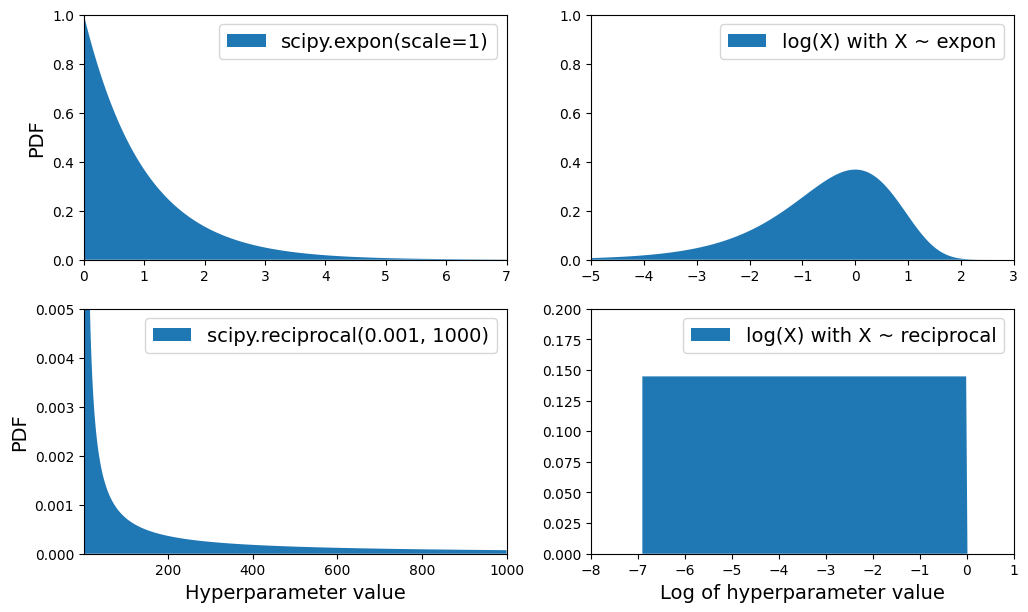

In [146]:
# extra code – shows the difference between expon and reciprocal

from scipy.stats import reciprocal

xs1 = np.linspace(0, 7, 500)
expon_distrib = expon(scale=1).pdf(xs1)

log_xs2 = np.linspace(-5, 3, 500)
log_expon_distrib = np.exp(log_xs2 - np.exp(log_xs2))

xs3 = np.linspace(0.001, 1000, 500)
reciprocal_distrib = reciprocal(0.001, 1000).pdf(xs3)

log_xs4 = np.linspace(np.log(0.001), np.log(1000), 500)
log_reciprocal_distrib = uniform(np.log(0.001), np.log(1000)).pdf(log_xs4)

plt.figure(figsize=(12, 7))

plt.subplot(2, 2, 1)
plt.fill_between(xs1, expon_distrib,
                 label="scipy.expon(scale=1)")
plt.ylabel("PDF")
plt.legend()
plt.axis([0, 7, 0, 1])

plt.subplot(2, 2, 2)
plt.fill_between(log_xs2, log_expon_distrib,
                 label="log(X) with X ~ expon")
plt.legend()
plt.axis([-5, 3, 0, 1])

plt.subplot(2, 2, 3)
plt.fill_between(xs3, reciprocal_distrib,
                 label="scipy.reciprocal(0.001, 1000)")
plt.xlabel("Hyperparameter value")
plt.ylabel("PDF")
plt.legend()
plt.axis([0.001, 1000, 0, 0.005])

plt.subplot(2, 2, 4)
plt.fill_between(log_xs4, log_reciprocal_distrib,
                 label="log(X) with X ~ reciprocal")
plt.xlabel("Log of hyperparameter value")
plt.legend()
plt.axis([-8, 1, 0, 0.2])

plt.show()

## Analyze the Best Models and Their Errors

In [147]:
final_model = rnd_search.best_estimator_  # includes preprocessing
feature_importances = final_model["random_forest"].feature_importances_
feature_importances.round(2)

array([0.08, 0.05, 0.05, 0.06, 0.05, 0.06, 0.05, 0.05, 0.05, 0.04, 0.  ,
       0.  , 0.  , 0.  , 0.  , 0.01, 0.  , 0.01, 0.06, 0.02, 0.  , 0.  ,
       0.  , 0.01, 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ,
       0.  , 0.  , 0.  , 0.  , 0.01, 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ,
       0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.03, 0.  , 0.  , 0.  ,
       0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.03, 0.  ,
       0.  , 0.01, 0.  , 0.  , 0.01, 0.  , 0.  , 0.01, 0.  , 0.  , 0.  ,
       0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ,
       0.03, 0.  , 0.01, 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.01,
       0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ,
       0.  , 0.  , 0.01, 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ,
       0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ,
       0.  , 0.  , 0.01, 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ,
       0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.

In [148]:
sorted(zip(feature_importances,
           final_model["preprocessing"].get_feature_names_out()),
           reverse=True)

[(0.07761107832844458, 'pipeline-1__Price_in_thousands'),
 (0.060556640925972724, 'pipeline-2__Manufacturer_Ford'),
 (0.058516876324958327, 'pipeline-1__Wheelbase'),
 (0.057187329781597546, 'pipeline-1__Length'),
 (0.05475475943841249, 'pipeline-1__Horsepower'),
 (0.05352918295842217, 'pipeline-1__Fuel_efficiency'),
 (0.05069758871861667, 'pipeline-1__Fuel_capacity'),
 (0.05048686633595606, 'pipeline-1__Engine_size'),
 (0.048513196737322524, 'pipeline-1__Width'),
 (0.04843501984003576, 'pipeline-1__Curb_weight'),
 (0.04217401131823263, 'pipeline-1__Power_perf_factor'),
 (0.033505853462418606, 'pipeline-2__Model_Explorer'),
 (0.029293602099921035, 'pipeline-2__Model_Accord'),
 (0.027048236771697858, 'pipeline-2__Model_Taurus'),
 (0.02668806343501473, 'pipeline-2__Model_Camry'),
 (0.024080741019683615, 'pipeline-2__Manufacturer_Honda'),
 (0.014425486382424151, 'pipeline-2__Model_Civic'),
 (0.014035477625334573, 'pipeline-2__Manufacturer_Toyota'),
 (0.011474576627691174, 'pipeline-2__Vehi

## Evaluate Your System on the Test Set

In [149]:
X_test = strat_test_set.drop("Sales_in_thousands", axis=1)
y_test = strat_test_set["Sales_in_thousands"].copy()

final_predictions = final_model.predict(X_test)

final_rmse = mean_squared_error(y_test, final_predictions, squared=False)
print(final_rmse)

81.90439307347339


We can compute a 95% confidence interval for the test RMSE:

In [150]:
from scipy import stats

confidence = 0.95
squared_errors = (final_predictions - y_test) ** 2
np.sqrt(stats.t.interval(confidence, len(squared_errors) - 1,
                         loc=squared_errors.mean(),
                         scale=stats.sem(squared_errors)))

C:\Users\raymo\AppData\Local\Temp\ipykernel_23676\3383173970.py:5: RuntimeWarning: invalid value encountered in sqrt
  np.sqrt(stats.t.interval(confidence, len(squared_errors) - 1,


array([         nan, 131.84251379])

We could compute the interval manually like this:

In [151]:
# extra code – shows how to compute a confidence interval for the RMSE
m = len(squared_errors)
mean = squared_errors.mean()
tscore = stats.t.ppf((1 + confidence) / 2, df=m - 1)
tmargin = tscore * squared_errors.std(ddof=1) / np.sqrt(m)
np.sqrt(mean - tmargin), np.sqrt(mean + tmargin)

C:\Users\raymo\AppData\Local\Temp\ipykernel_23676\2993801940.py:6: RuntimeWarning: invalid value encountered in sqrt
  np.sqrt(mean - tmargin), np.sqrt(mean + tmargin)


(nan, 131.8425137900481)

Alternatively, we could use a z-score rather than a t-score. Since the test set is not too small, it won't make a big difference:

In [152]:
# extra code – computes a confidence interval again using a z-score
zscore = stats.norm.ppf((1 + confidence) / 2)
zmargin = zscore * squared_errors.std(ddof=1) / np.sqrt(m)
np.sqrt(mean - zmargin), np.sqrt(mean + zmargin)

C:\Users\raymo\AppData\Local\Temp\ipykernel_23676\1450656841.py:4: RuntimeWarning: invalid value encountered in sqrt
  np.sqrt(mean - zmargin), np.sqrt(mean + zmargin)


(nan, 130.25403505873908)

## Model persistence using joblib

Save the final model:

In [153]:
import joblib

joblib.dump(final_model, "my_car_model.pkl")

['my_car_model.pkl']

Now you can deploy this model to production. For example, the following code could be a script that would run in production:

In [154]:
import joblib

# extra code – excluded for conciseness
from sklearn.cluster import KMeans
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics.pairwise import rbf_kernel

def column_ratio(X):
    return X[:, [0]] / X[:, [1]]

#class ClusterSimilarity(BaseEstimator, TransformerMixin):
#    [...]

final_model_reloaded = joblib.load("my_car_model.pkl")

new_data = car.iloc[:5]  # pretend these are new districts
predictions = final_model_reloaded.predict(new_data)

In [155]:
predictions

array([50.73057, 24.6082 ,  7.82366, 11.26111, 68.05933])

You could use pickle instead, but joblib is more efficient.

# Exercise solutions

## 1.

Exercise: _Try a Support Vector Machine regressor (`sklearn.svm.SVR`) with various hyperparameters, such as `kernel="linear"` (with various values for the `C` hyperparameter) or `kernel="rbf"` (with various values for the `C` and `gamma` hyperparameters). Note that SVMs don't scale well to large datasets, so you should probably train your model on just the first 5,000 instances of the training set and use only 3-fold cross-validation, or else it will take hours. Don't worry about what the hyperparameters mean for now (see the SVM notebook if you're interested). How does the best `SVR` predictor perform?_

In [156]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVR

param_grid = [
        {'svr__kernel': ['linear'], 'svr__C': [10., 30., 100., 300., 1000.,
                                               3000., 10000., 30000.0]},
        {'svr__kernel': ['rbf'], 'svr__C': [1.0, 3.0, 10., 30., 100., 300.,
                                            1000.0],
         'svr__gamma': [0.01, 0.03, 0.1, 0.3, 1.0, 3.0]},
    ]

svr_pipeline = Pipeline([("preprocessing", preprocessing), ("svr", SVR())])
grid_search = GridSearchCV(svr_pipeline, param_grid, cv=3,
                           scoring='neg_root_mean_squared_error')
grid_search.fit(car.iloc[:5000], car_labels.iloc[:5000])

GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('preprocessing',
                                        ColumnTransformer(transformers=[('pipeline-1',
                                                                         Pipeline(steps=[('simpleimputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('standardscaler',
                                                                                          StandardScaler())]),
                                                                         <sklearn.compose._column_transformer.make_column_selector object at 0x0000022AD6CD18E0>),
                                                                        ('pipeline-2',
                                                                         Pipeline(steps=[('simpleimputer',
                                                                                          Simpl...
                                                                         <sklearn.compose._column_transformer.make_column_selector object at 0x0000022AD6CD10A0>)])),
                                       ('svr', SVR())]),
             param_grid=[{'svr__C': [10.0, 30.0, 100.0, 300.0, 1000.0, 3000.0,
                                     10000.0, 30000.0],
                          'svr__kernel': ['linear']},
                         {'svr__C': [1.0, 3.0, 10.0, 30.0, 100.0, 300.0,
                                     1000.0],
                          'svr__gamma': [0.01, 0.03, 0.1, 0.3, 1.0, 3.0],
                          'svr__kernel': ['rbf']}],
             scoring='neg_root_mean_squared_error')

The best model achieves the following score (evaluated using 3-fold cross validation):

In [157]:
svr_grid_search_rmse = -grid_search.best_score_
svr_grid_search_rmse

47.79137233699489

That's much worse than the `RandomForestRegressor` (but to be fair, we trained the model on much less data). Let's check the best hyperparameters found:

In [158]:
grid_search.best_params_

{'svr__C': 1000.0, 'svr__gamma': 0.01, 'svr__kernel': 'rbf'}

The linear kernel seems better than the RBF kernel. Notice that the value of `C` is the maximum tested value. When this happens you definitely want to launch the grid search again with higher values for `C` (removing the smallest values), because it is likely that higher values of `C` will be better.

## 2.

Exercise: _Try replacing the `GridSearchCV` with a `RandomizedSearchCV`._

**Warning:** the following cell will take several minutes to run. You can specify `verbose=2` when creating the `RandomizedSearchCV` if you want to see the training details.

In [159]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import expon, reciprocal

# see https://docs.scipy.org/doc/scipy/reference/stats.html
# for `expon()` and `reciprocal()` documentation and more probability distribution functions.

# Note: gamma is ignored when kernel is "linear"
param_distribs = {
        'svr__kernel': ['linear', 'rbf'],
        'svr__C': reciprocal(20, 200_000),
        'svr__gamma': expon(scale=1.0),
    }

rnd_search = RandomizedSearchCV(svr_pipeline,
                                param_distributions=param_distribs,
                                n_iter=50, cv=3,
                                scoring='neg_root_mean_squared_error',
                                random_state=42)
rnd_search.fit(car.iloc[:5000], car_labels.iloc[:5000])

RandomizedSearchCV(cv=3,
                   estimator=Pipeline(steps=[('preprocessing',
                                              ColumnTransformer(transformers=[('pipeline-1',
                                                                               Pipeline(steps=[('simpleimputer',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('standardscaler',
                                                                                                StandardScaler())]),
                                                                               <sklearn.compose._column_transformer.make_column_selector object at 0x0000022AD6CD18E0>),
                                                                              ('pipeline-2',
                                                                               Pipeline(steps=[('simpleimputer'...
                                                                               <sklearn.compose._column_transformer.make_column_selector object at 0x0000022AD6CD10A0>)])),
                                             ('svr', SVR())]),
                   n_iter=50,
                   param_distributions={'svr__C': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x0000022AD66E49A0>,
                                        'svr__gamma': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x0000022AD02231F0>,
                                        'svr__kernel': ['linear', 'rbf']},
                   random_state=42, scoring='neg_root_mean_squared_error')

The best model achieves the following score (evaluated using 3-fold cross validation):

In [160]:
svr_rnd_search_rmse = -rnd_search.best_score_
svr_rnd_search_rmse

48.07718768843711

Now that's really much better, but still far from the `RandomForestRegressor`'s performance. Let's check the best hyperparameters found:

In [161]:
rnd_search.best_params_

{'svr__C': 21.344953672647435,
 'svr__gamma': 0.023332523598323388,
 'svr__kernel': 'linear'}

This time the search found a good set of hyperparameters for the RBF kernel. Randomized search tends to find better hyperparameters than grid search in the same amount of time.

Note that we used the `expon()` distribution for `gamma`, with a scale of 1, so `RandomSearch` mostly searched for values roughly of that scale: about 80% of the samples were between 0.1 and 2.3 (roughly 10% were smaller and 10% were larger):

In [162]:
np.random.seed(42)

s = expon(scale=1).rvs(100_000)  # get 100,000 samples
((s > 0.105) & (s < 2.29)).sum() / 100_000

0.80066

We used the `reciprocal()` distribution for `C`, meaning we did not have a clue what the optimal scale of `C` was before running the random search. It explored the range from 20 to 200 just as much as the range from 2,000 to 20,000 or from 20,000 to 200,000.

## 3.

Exercise: _Try adding a `SelectFromModel` transformer in the preparation pipeline to select only the most important attributes._

Let's create a new pipeline that runs the previously defined preparation pipeline, and adds a `SelectFromModel` transformer based on a `RandomForestRegressor` before the final regressor:

In [163]:
from sklearn.feature_selection import SelectFromModel

selector_pipeline = Pipeline([
    ('preprocessing', preprocessing),
    ('selector', SelectFromModel(RandomForestRegressor(random_state=42),
                                 threshold=0.005)),  # min feature importance
    ('svr', SVR(C=rnd_search.best_params_["svr__C"],
                gamma=rnd_search.best_params_["svr__gamma"],
                kernel=rnd_search.best_params_["svr__kernel"])),
])

In [164]:
selector_rmses = -cross_val_score(selector_pipeline,
                                  car.iloc[:5000],
                                  car_labels.iloc[:5000],
                                  scoring="neg_root_mean_squared_error",
                                  cv=3)
pd.Series(selector_rmses).describe()

count     3.000000
mean     50.095943
std      15.455636
min      38.401441
25%      41.334817
50%      44.268193
75%      55.943194
max      67.618195
dtype: float64

Oh well, feature selection does not seem to help. But maybe that's just because the threshold we used was not optimal. Perhaps try tuning it using random search or grid search?

## 4.

Exercise: _Try creating a custom transformer that trains a k-Nearest Neighbors regressor (`sklearn.neighbors.KNeighborsRegressor`) in its `fit()` method, and outputs the model's predictions in its `transform()` method. Then add this feature to the preprocessing pipeline, using latitude and longitude as the inputs to this transformer. This will add a feature in the model that corresponds to the car median price of the nearest districts._

Rather than restrict ourselves to k-Nearest Neighbors regressors, let's create a transformer that accepts any regressor. For this, we can extend the `MetaEstimatorMixin` and have a required `estimator` argument in the constructor. The `fit()` method must work on a clone of this estimator, and it must also save `feature_names_in_`. The `MetaEstimatorMixin` will ensure that `estimator` is listed as a required parameters, and it will update `get_params()` and `set_params()` to make the estimator's hyperparameters available for tuning. Lastly, we create a `get_feature_names_out()` method: the output column name is the ...

In [165]:
# from sklearn.neighbors import KNeighborsRegressor
# from sklearn.base import MetaEstimatorMixin, clone

# class FeatureFromRegressor(MetaEstimatorMixin, BaseEstimator, TransformerMixin):
#     def __init__(self, estimator):
#         self.estimator = estimator

#     def fit(self, X, y=None):
#         estimator_ = clone(self.estimator)
#         estimator_.fit(X, y)
#         self.estimator_ = estimator_
#         self.n_features_in_ = self.estimator_.n_features_in_
#         if hasattr(self.estimator, "feature_names_in_"):
#             self.feature_names_in_ = self.estimator.feature_names_in_
#         return self  # always return self!
    
#     def transform(self, X):
#         check_is_fitted(self)
#         predictions = self.estimator_.predict(X)
#         if predictions.ndim == 1:
#             predictions = predictions.reshape(-1, 1)
#         return predictions

#     def get_feature_names_out(self, names=None):
#         check_is_fitted(self)
#         n_outputs = getattr(self.estimator_, "n_outputs_", 1)
#         estimator_class_name = self.estimator_.__class__.__name__
#         estimator_short_name = estimator_class_name.lower().replace("_", "")
#         return [f"{estimator_short_name}_prediction_{i}"
#                 for i in range(n_outputs)]

Let's ensure it complies to Scikit-Learn's API:

In [166]:
# from sklearn.utils.estimator_checks import check_estimator

# check_estimator(FeatureFromRegressor(KNeighborsRegressor()))

Good! Now let's test it:

In [167]:
# car["Horsepower"]=car["Horsepower"].fillna(car["Horsepower"].median())
# car["Fuel_efficiency"]=car["Fuel_efficiency"].fillna(car["Fuel_efficiency"].median())
# knn_reg = KNeighborsRegressor(n_neighbors=3, weights="distance")
# knn_transformer = FeatureFromRegressor(knn_reg)
# car_features = car[["Horsepower", "Fuel_efficiency"]]
# knn_transformer.fit_transform(car_features,car_labels)

And what does its output feature name look like?

In [168]:
# knn_transformer.get_feature_names_out()

Okay, now let's include this transformer in our preprocessing pipeline:

In [169]:
# from sklearn.base import clone

# transformers = [(name, clone(transformer), columns)
#                for name, transformer, columns in preprocessing.transformers]
# geo_index = [name for name, _, _ in transformers].index("geo")
# transformers[geo_index] = ("geo", knn_transformer, ["latitude", "longitude"])

# new_geo_preprocessing = ColumnTransformer(transformers)

In [170]:
# new_geo_pipeline = Pipeline([
#     ('preprocessing', new_geo_preprocessing),
#     ('svr', SVR(C=rnd_search.best_params_["svr__C"],
#                 gamma=rnd_search.best_params_["svr__gamma"],
#                 kernel=rnd_search.best_params_["svr__kernel"])),
# ])

In [171]:
# new_pipe_rmses = -cross_val_score(new_geo_pipeline,
#                                   car.iloc[:5000],
#                                   car_labels.iloc[:5000],
#                                   scoring="neg_root_mean_squared_error",
#                                   cv=3)
# pd.Series(new_pipe_rmses).describe()

Yikes, that's terrible! Apparently the cluster similarity features were much better. But perhaps we should tune the `KNeighborsRegressor`'s hyperparameters? That's what the next exercise is about.

## 5.

Exercise: _Automatically explore some preparation options using `RandomSearchCV`._

In [172]:
# param_distribs = {
#     "preprocessing__geo__estimator__n_neighbors": range(1, 30),
#     "preprocessing__geo__estimator__weights": ["distance", "uniform"],
#     "svr__C": reciprocal(20, 200_000),
#     "svr__gamma": expon(scale=1.0),
# }

# new_geo_rnd_search = RandomizedSearchCV(new_geo_pipeline,
#                                         param_distributions=param_distribs,
#                                         n_iter=50,
#                                         cv=3,
#                                         scoring='neg_root_mean_squared_error',
#                                         random_state=42)
# new_geo_rnd_search.fit(car.iloc[:5000], car_labels.iloc[:5000])

In [173]:
# new_geo_rnd_search_rmse = -new_geo_rnd_search.best_score_
# new_geo_rnd_search_rmse

Oh well... at least we tried! It looks like the cluster similarity features are definitely better than the KNN feature. But perhaps you could try having both? And maybe training on the full training set would help as well.

## 6.

Exercise: _Try to implement the `StandardScalerClone` class again from scratch, then add support for the `inverse_transform()` method: executing `scaler.inverse_transform(scaler.fit_transform(X))` should return an array very close to `X`. Then add support for feature names: set `feature_names_in_` in the `fit()` method if the input is a DataFrame. This attribute should be a NumPy array of column names. Lastly, implement the `get_feature_names_out()` method: it should have one optional `input_features=None` argument. If passed, the method should check that its length matches `n_features_in_`, and it should match `feature_names_in_` if it is defined, then `input_features` should be returned. If `input_features` is `None`, then the method should return `feature_names_in_` if it is defined or `np.array(["x0", "x1", ...])` with length `n_features_in_` otherwise._

In [174]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_array, check_is_fitted

class StandardScalerClone(BaseEstimator, TransformerMixin):
    def __init__(self, with_mean=True):  # no *args or **kwargs!
        self.with_mean = with_mean

    def fit(self, X, y=None):  # y is required even though we don't use it
        X_orig = X
        X = check_array(X)  # checks that X is an array with finite float values
        self.mean_ = X.mean(axis=0)
        self.scale_ = X.std(axis=0)
        self.n_features_in_ = X.shape[1]  # every estimator stores this in fit()
        if hasattr(X_orig, "columns"):
            self.feature_names_in_ = np.array(X_orig.columns, dtype=object)
        return self  # always return self!

    def transform(self, X):
        check_is_fitted(self)  # looks for learned attributes (with trailing _)
        X = check_array(X)
        if self.n_features_in_ != X.shape[1]:
            raise ValueError("Unexpected number of features")
        if self.with_mean:
            X = X - self.mean_
        return X / self.scale_
    
    def inverse_transform(self, X):
        check_is_fitted(self)
        X = check_array(X)
        if self.n_features_in_ != X.shape[1]:
            raise ValueError("Unexpected number of features")
        X = X * self.scale_
        return X + self.mean_ if self.with_mean else X
    
    def get_feature_names_out(self, input_features=None):
        if input_features is None:
            return getattr(self, "feature_names_in_",
                           [f"x{i}" for i in range(self.n_features_in_)])
        else:
            if len(input_features) != self.n_features_in_:
                raise ValueError("Invalid number of features")
            if hasattr(self, "feature_names_in_") and not np.all(
                self.feature_names_in_ == input_features
            ):
                raise ValueError("input_features ≠ feature_names_in_")
            return input_features

Let's test our custom transformer:

In [175]:
from sklearn.utils.estimator_checks import check_estimator
 
check_estimator(StandardScalerClone())

No errors, that's a great start, we respect the Scikit-Learn API.

Now let's ensure the transformation works as expected:

In [176]:
np.random.seed(42)
X = np.random.rand(1000, 3)

scaler = StandardScalerClone()
X_scaled = scaler.fit_transform(X)

assert np.allclose(X_scaled, (X - X.mean(axis=0)) / X.std(axis=0))

How about setting `with_mean=False`?

In [177]:
scaler = StandardScalerClone(with_mean=False)
X_scaled_uncentered = scaler.fit_transform(X)

assert np.allclose(X_scaled_uncentered, X / X.std(axis=0))

And does the inverse work?

In [178]:
scaler = StandardScalerClone()
X_back = scaler.inverse_transform(scaler.fit_transform(X))

assert np.allclose(X, X_back)

How about the feature names out?

In [179]:
assert np.all(scaler.get_feature_names_out() == ["x0", "x1", "x2"])
assert np.all(scaler.get_feature_names_out(["a", "b", "c"]) == ["a", "b", "c"])

And if we fit a DataFrame, are the feature in and out ok?

In [180]:
df = pd.DataFrame({"a": np.random.rand(100), "b": np.random.rand(100)})
scaler = StandardScalerClone()
X_scaled = scaler.fit_transform(df)

assert np.all(scaler.feature_names_in_ == ["a", "b"])
assert np.all(scaler.get_feature_names_out() == ["a", "b"])

All good! That's all for today! 😀

Congratulations! You already know quite a lot about Machine Learning. :)